# Úkol č. 1 - redukce dimenzionality a binární klasifikace

* Termíny jsou uvedeny na [courses.fit.cvut.cz/BI-ML2/homeworks/index.html](https://courses.fit.cvut.cz/BI-ML2/homeworks/index.html).
* Pokud odevzdáte úkol po prvním termínu ale před nejzazším termínem, budete penalizování -12 body, pozdější odevzdání je bez bodu.
* V rámci tohoto úkolu se musíte vypořádat s vysokou dimenzí problému a poté úspěšně aplikovat vhodný klasfikační model.
    
> **Úkoly jsou zadány tak, aby Vám daly prostor pro invenci. Vymyslet _jak přesně_ budete úkol řešit, je důležitou součástí zadání a originalita či nápaditost bude také hodnocena!**

Využívejte buňky typu `Markdown` k vysvětlování Vašeho postupu. Za nepřehlednost budou strhávány body.

## Zdroj dat

 * Zdrojem dat jsou soubory `train.csv` a `evaluate.csv`.
 * Jedná se o obrázky 28x28 pixelů ve stupních šedi, které byly získány z [Fashion Mnist datasetu](https://www.kaggle.com/datasets/zalando-research/fashionmnist).
 * Soubor `train.csv` obsahuje trénovací data.
 * Cílová (vysvětlovaná) proměnná se jmenuje **label**.
 * Soubor `evaluate.csv` obsahuje testovací data bez hodnot skutečných labelů.

## Pokyny k vypracování

**Body zadání**, za jejichž (poctivé) vypracování získáte **25 bodů**:
  * V notebooku načtěte data ze souboru `train.csv`. Vhodným způsobem si je rozdělte na podmnožiny, které Vám poslouží pro trénování, porovnávání modelů a následnou predikci výkonnosti finálního modelu.
  * Proveďte základní průzkum dat a svá pozorování diskutujte. Některé obrázky také zobrazte.
  * Postupně aplikujte modely **SVM**, **naivní Bayesův klasifikátor** a **LDA**, přičemž pro každý z nich:
      * Okomentujte vhodnost daného modelu pro daný typ úlohy.
      * Vyberte si hlavní hyperparametry k ladění (pokud model má hyperparametry) a najděte jejich nejlepší hodnoty.
      * U SVM vyzkoušejte alespoň dvě různé jádrové funkce.
      * Získané výsledky vždy řádně okomentujte.
<br/><br/>

  * Použijte natrénovaný generativní model Naivního Bayesova klasifikátoru nebo Lineární diskriminační analýzy (podle Vaší volby) a vygenerujte pro každou třídu 5 datových bodů, které následně přetransformujte do rozměrů 28x28 a zobrazte pomocí `imshow`. Diskutujte kvalitu vygenerovaných dat. K vygenerování můžete využít funkci [multivariate_normal](https://numpy.org/doc/2.2/reference/random/generated/numpy.random.multivariate_normal.html) z `numpy`.

  * Postupně aplikujte metody redukce dimenzionality PCA a LLE, přičemž pro každou z nich: 
      * Zopakujte předchozí kroky aplikace modelů (žádné další generování už nedělejte) a pokuste se je vylepšit.
      * Zkoumejte jaká dimenze je z hlediska výkonnosti finálního modelu nejlepší.
      * Získané výsledky vždy řádně okomentujte.
<br/><br/>
    
  * Ze všech zkoušených možností vyberte finální model a odhadněte, jakou přesnost můžete očekávat na nových datech, která jste doposud neměli k dispozici. _Pozor na metodické chyby!_
  
  * Nakonec načtěte vyhodnocovací data ze souboru`evaluate.csv`. Pomocí finálního modelu napočítejte predikce pro tyto data (vysvětlovaná proměnná v nich již není). Vytvořte soubor `results.csv`, ve kterém získané predikce uložíte do sloupce **label** a identifikátory do sloupce **ID**. Tento soubor též odevzdejte (uložte do projektu vedle notebooku).
   
       * Ukázka, jak by mělo vypadat prvních několik řádků souboru `results.csv` (obecně s jinými hodnotami):
  
```
ID,label
0,0
1,1
...
```

## Poznámky k odevzdání

  * Řiďte se pokyny ze stránky https://courses.fit.cvut.cz/BI-ML2/homeworks/index.html.
  * Vytvořte i csv soubor `results.csv` s predikcemi a uložte ho v rámci projektu vedle ipython notebooku.

## 0. Importing libraries

In [38]:
import pandas as pd
import math
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.tree import DecisionTreeRegressor
from sklearn.utils import resample
import sklearn.metrics as metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, accuracy_score, ConfusionMatrixDisplay
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.decomposition import PCA
from sklearn.manifold import LocallyLinearEmbedding
import warnings

random_seed = 42

## 1. Data preparation

### 1. Dataset overview

Reading a dataset and show it's sizes.

In [2]:
df = pd.read_csv("train.csv")
print("Dataset sizes are: " + str(df.shape))

Dataset sizes are: (1500, 785)


Let's see dataset overview:

In [3]:
display(df)

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,95,132,90,0,0,0
2,1,0,0,0,0,0,0,3,0,23,...,94,68,44,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,1,0,...,57,0,0,0,26,71,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,2,0,6,156,149,78,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1495,0,0,0,0,0,0,0,0,0,0,...,35,0,0,1,0,0,0,0,0,0
1496,0,0,0,0,0,0,0,0,0,0,...,198,96,0,0,2,0,0,0,0,0
1497,1,0,0,0,0,0,0,0,0,0,...,149,33,0,0,0,0,0,0,0,0
1498,0,0,0,0,0,0,0,0,0,1,...,0,0,0,69,88,35,0,0,0,0


Describing our dataset.

In [4]:
df.describe()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
count,1500.000000,1500.0,1500.0,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,...,1500.000000,1500.000000,1500.0000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,0.494000,0.0,0.0,0.003333,0.014667,0.094000,0.172000,0.696667,1.560667,3.672000,...,45.751333,26.884000,12.8060,24.222667,36.824000,27.227333,10.798000,1.529333,0.129333,0.012667
std,0.500131,0.0,0.0,0.085599,0.196156,1.645692,1.935522,7.234884,12.065794,17.912854,...,60.907953,48.747801,32.4854,51.600777,65.053729,54.335598,31.792269,12.227598,3.098872,0.369591
min,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,4.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,86.000000,36.000000,1.0000,7.000000,55.500000,18.250000,0.000000,0.000000,0.000000,0.000000
max,1.000000,0.0,0.0,3.000000,5.000000,53.000000,52.000000,136.000000,216.000000,183.000000,...,240.000000,227.000000,231.0000,255.000000,249.000000,251.000000,244.000000,171.000000,97.000000,13.000000


Controlling missing values

In [5]:
print("Missing values count: ", df.isnull().sum().sum())

Missing values count:  0


Now we know that dataset looks clear and we can continue to data splitting.

### 2. Data splitting

Saving ``label`` values separately from other part of dataset and saving other part of dataset without ``label`` values, because it is target variable. 

In [6]:
y = df['label']
x = df.drop('label', axis=1)

Data splitting process

In [7]:
Xtrain, Xtest, ytrain, ytest = train_test_split(x, y, test_size=0.4, random_state=random_seed)

display(Xtrain.shape)
display(ytrain.shape)
display(Xtest.shape)
display(ytest.shape)

(900, 784)

(900,)

(600, 784)

(600,)

In [8]:
Xval, Xtest, yval, ytest = train_test_split(Xtest, ytest, test_size=0.5, random_state=random_seed)

display(Xval.shape)
display(yval.shape)
display(Xtest.shape)
display(ytest.shape)

(300, 784)

(300,)

(300, 784)

(300,)

Now we have all data divided to a 3 groups. Let's see a graph.

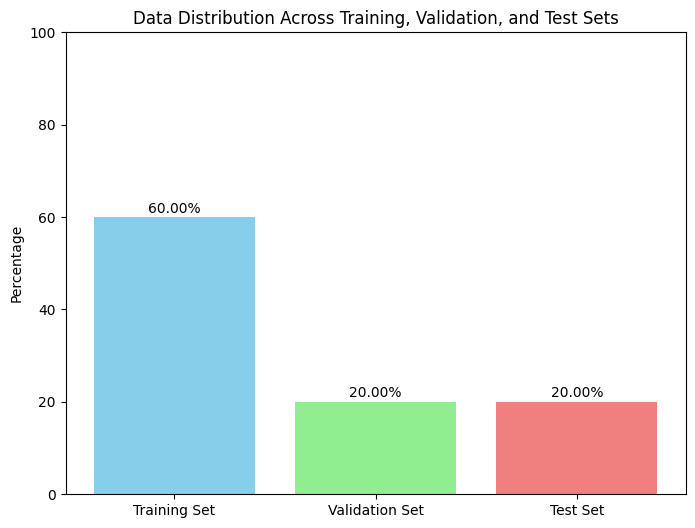

In [9]:
def plot_data_distribution(Xtrain, Xval, Xtest):
    sizes = [len(Xtrain), len(Xval), len(Xtest)]
    labels = ['Training Set', 'Validation Set', 'Test Set']
    percentages = [size / sum(sizes) * 100 for size in sizes]

    # Plot
    plt.figure(figsize=(8, 6))
    plt.bar(labels, percentages, color=['skyblue', 'lightgreen', 'lightcoral'])
    plt.title("Data Distribution Across Training, Validation, and Test Sets")
    plt.ylabel("Percentage")
    plt.ylim(0, 100)
    
    for i, v in enumerate(percentages):
        plt.text(i, v + 1, f"{v:.2f}%", ha='center', fontsize=10)

    plt.show()

plot_data_distribution(Xtrain, Xval, Xtest)

We apply different scaling methods to preprocess the data before training models. This ensures features are on a similar scale, improving model performance and stability. Each scaler helps handle different data distributions and potential outliers.  


In [10]:
scaler_standard = StandardScaler()
Xtrain_standard = scaler_standard.fit_transform(Xtrain) 
Xval_standard = scaler_standard.transform(Xval) 

scaler_minmax = MinMaxScaler()
Xtrain_minmax = scaler_minmax.fit_transform(Xtrain)  
Xval_minmax = scaler_minmax.transform(Xval) 
Xtest_minmax = scaler_minmax.transform(Xtest)

scaler_robust = RobustScaler()
Xtrain_robust = scaler_robust.fit_transform(Xtrain)  
Xval_robust = scaler_robust.transform(Xval) 
Xtest_robust = scaler_robust.transform(Xtest)

## 2. SVM, naive Bayes clasificator and LDA

### 1. SVM

#### Apply a Basic SVM Model

We will use a **Support Vector Machine (SVM)** with a **linear kernel** to classify the data and observe the results.

- **`kernel='linear'`** → Uses a **linear hyperplane** to separate the classes.
- **`C=1`** → Controls regularization. A higher `C` reduces misclassification but may lead to overfitting.
- **`random_state=random_seed`** → Ensures **reproducibility** of results.

Let's train the model and analyze its performance.

In [11]:
clf_SVM = SVC(kernel='linear', C=1, random_state=random_seed)

clf_SVM.fit(Xtrain_standard, ytrain) 
clf_SVM_accuracy_standard = metrics.accuracy_score(yval, clf_SVM.predict(Xval_standard)) 
print(f"Accuracy SVM with Standard Scaling: {clf_SVM_accuracy_standard} with hyperparameters kernel='linear', C=1, random_state=42")

clf_SVM.fit(Xtrain_minmax, ytrain) 
clf_SVM_accuracy_minmax = metrics.accuracy_score(yval, clf_SVM.predict(Xval_minmax)) 
print(f"Accuracy SVM with Min-Max Scaling: {clf_SVM_accuracy_minmax} with hyperparameters kernel='linear', C=1, random_state=42")

clf_SVM.fit(Xtrain_robust, ytrain)
clf_SVM_accuracy_robust = metrics.accuracy_score(yval, clf_SVM.predict(Xval_robust))
print(f"Accuracy SVM with Robust Scaling: {clf_SVM_accuracy_robust} with hyperparameters kernel='linear', C=1, random_state=42")

Accuracy SVM with Standard Scaling: 0.9 with hyperparameters kernel='linear', C=1, random_state=42
Accuracy SVM with Min-Max Scaling: 0.9133333333333333 with hyperparameters kernel='linear', C=1, random_state=42
Accuracy SVM with Robust Scaling: 0.89 with hyperparameters kernel='linear', C=1, random_state=42


#### SVM Performance with Different Scaling Techniques

- **Standard Scaling**: Accuracy = **0.9**
- **Min-Max Scaling**: Accuracy = **0.9133**
- **Robust Scaling**: Accuracy = **0.89**

#### Conclusion
**Min-Max Scaling** gave the best performance with an accuracy of **0.9133**.


#### Hyperparameters tuning:

In [12]:
param_grid = {
    'C': range(1, 40),
    'gamma': ['scale', 'auto'],
    'kernel': ['rbf', 'linear', 'poly', 'sigmoid']
}

param_comb = ParameterGrid(param_grid)

val_metric = []
for params in param_comb:
    clfSVM = SVC(**params, random_state=random_seed)
    clfSVM.fit(Xtrain_minmax, ytrain)
    val_metric.append(metrics.accuracy_score(yval, clfSVM.predict(Xval_minmax)))

best_params_clfSVM = param_comb[np.argmax(val_metric)]
best_accuracy_clfSVM = max(val_metric)

In [14]:
clfSVMb = SVC(**best_params_clfSVM, random_state=random_seed)
clfSVMb.fit(Xtrain_minmax, ytrain)
print(f"Best hyperparameters: {best_params_clfSVM}")
print('Accuracy on validation data: {0:.4f}'.format(metrics.accuracy_score(yval, clfSVMb.predict(Xval_minmax))))

Best hyperparameters: {'kernel': 'rbf', 'gamma': 'auto', 'C': 13}
Accuracy on validation data: 0.9467


#### Advantages and Disadvantages of LDA for Our Dataset

#### ✅ Advantages  
- Works well in high-dimensional spaces.  
- Robust to overfitting with proper regularization.  
- Effective for non-linearly separable data (RBF kernel).  
- Handles outliers with kernel choices.  

#### ❌ Disadvantages
- Computationally expensive for large datasets.  
- Requires careful hyperparameter tuning.  
- Hard to interpret compared to decision trees.  
- Sensitive to feature scaling.  

#### 🔍 Conclusion  
SVM performs well with proper scaling and tuning, but may not scale efficiently for very large datasets.


### 2. Naive Bayes clasifier

#### Why GaussianNB?

We chose **GaussianNB** because our dataset contains **continuous numerical features**, which align well with the assumption of **normal distribution** in Gaussian Naive Bayes.

##### Why not other types?
- **MultinomialNB & ComplementNB** – Designed for **frequency-based** features (e.g., text data).  
- **BernoulliNB** – Works with **binary** features (0/1).  
- **CategoricalNB** – Used for **discrete categorical** variables, while our features are numerical.  

Thus, **GaussianNB** is the best fit for our dataset.


Train and evaluate **GaussianNB** with different scaling methods

In [15]:
clf_bayes = GaussianNB()

clf_bayes.fit(Xtrain_minmax, ytrain)
print(f"Training accuracy (Min-Max Scaling): {clf_bayes.score(Xtrain_minmax, ytrain):.4f}")
print(f"Validation accuracy (Min-Max Scaling): {clf_bayes.score(Xval_minmax, yval):.4f}")

clf_bayes.fit(Xtrain_standard, ytrain)
print(f"\nTraining accuracy (Standard Scaling): {clf_bayes.score(Xtrain_standard, ytrain):.4f}")
print(f"Validation accuracy (Standard Scaling): {clf_bayes.score(Xval_standard, yval):.4f}")

clf_bayes.fit(Xtrain_robust, ytrain)
print(f"\nTraining accuracy (Robust Scaling): {clf_bayes.score(Xtrain_robust, ytrain):.4f}")
print(f"Validation accuracy (Robust Scaling): {clf_bayes.score(Xval_robust, yval):.4f}")


Training accuracy (Min-Max Scaling): 0.8789
Validation accuracy (Min-Max Scaling): 0.8367

Training accuracy (Standard Scaling): 0.8744
Validation accuracy (Standard Scaling): 0.8333

Training accuracy (Robust Scaling): 0.8822
Validation accuracy (Robust Scaling): 0.8367


All three scaling methods yielded similar results, with slight variations in accuracy.  
- **Min-Max Scaling** and **Robust Scaling** achieved the highest validation accuracy (0.8367) with 49 misclassified samples.  
- **Standard Scaling** performed slightly worse, with a validation accuracy of 0.8333 and 50 misclassified samples.  

Overall, **Robust Scaling** provides a small advantage in training accuracy, but the differences are minimal. Any of the three methods could be used without significantly impacting the model's performance.


#### Hyperparameters tuning:

In [16]:
param_grid = {'var_smoothing': np.logspace(-12, 0, 1000)}

param_comb = ParameterGrid(param_grid)

val_metric = []
for params in param_comb:
    clf_bayes = GaussianNB(**params)
    clf_bayes.fit(Xtrain_robust, ytrain)
    val_metric.append(metrics.accuracy_score(yval, clf_bayes.predict(Xval_robust)))

# Get best parameters
best_params_bayes = param_comb[np.argmax(val_metric)]
best_accuracy_bayes = max(val_metric)
print(f"Best var_smoothing: {best_params_bayes['var_smoothing']}")
print(f"Best validation accuracy: {best_accuracy_bayes:.4f}")

Best var_smoothing: 2.1102034285685966e-08
Best validation accuracy: 0.8433


#### Advantages and Disadvantages of LDA for Our Dataset
#### ✅ Advantages
- Fast training, efficient for large datasets  
- Works well with small data and numerical features  
- Simple and interpretable  

#### ❌ Disadvantages
- Assumes feature independence (often unrealistic)  
- Sensitive to feature distribution (normality assumption)  
- Struggles with complex decision boundaries and imbalanced data  
#### 🔍 Conclusion  
🔹 **Good as a baseline, but may be outperformed by more complex models.** 🚀


### 3. LDA

In [40]:
lda = LinearDiscriminantAnalysis()

lda.fit(Xtrain_minmax, ytrain)
print(f"Validation accuracy (Min-Max Scaling): {lda.score(Xval_minmax, yval):.4f}")

ypred_minmax = lda.predict(Xval_minmax)

lda.fit(Xtrain_standard, ytrain)
print(f"Validation accuracy (Standard Scaling): {lda.score(Xval_standard, yval):.4f}")

ypred_standard = lda.predict(Xval_standard)


lda.fit(Xtrain_robust, ytrain)
print(f"Validation accuracy (Robust Scaling): {lda.score(Xval_robust, yval):.4f}")

ypred_robust = lda.predict(Xval_robust)


Validation accuracy (Min-Max Scaling): 0.8000
Validation accuracy (Standard Scaling): 0.8000
Validation accuracy (Robust Scaling): 0.8000


#### Model Performance Across Different Scales

Normalization has little effect on LDA because it models data using class covariances, making it scale-invariant. The algorithm focuses on distribution shapes rather than absolute feature values.

#### Hyperparameters tuning:

In [18]:
param_grid = {
    'solver': ['lsqr', 'eigen'],
    'shrinkage': np.arange(0.01, 1, 0.01),
    'n_components': range(1, min(len(np.unique(ytrain)), Xtrain.shape[1]))
}

param_comb = ParameterGrid(param_grid)

val_metric = []
for params in param_comb:
    clflda = LinearDiscriminantAnalysis(**params)
    clflda.fit(Xtrain, ytrain)
    val_metric.append(metrics.accuracy_score(yval, clflda.predict(Xval)))

best_params_clflda = param_comb[np.argmax(val_metric)]
best_accuracy_clflda = max(val_metric)
print(f"Best hyperparameters: {best_params_clflda}")
print(f"Best validation accuracy: {best_accuracy_clflda:.4f}")

Best hyperparameters: {'solver': 'lsqr', 'shrinkage': np.float64(0.04), 'n_components': 1}
Best validation accuracy: 0.9200


#### Advantages and Disadvantages of LDA for Our Dataset

#### ✅ Advantages
- **High Validation Accuracy**: Achieved 92% accuracy, indicating good generalization.
- **Feature Reduction**: Using `n_components=1` reduces dimensionality while maintaining performance.
- **Regularization**: `shrinkage=0.04` helps improve stability and prevent overfitting.

#### ❌ Disadvantages
- **Linear Assumptions**: LDA assumes normality and equal covariance, which may not hold for all data distributions.
- **Limited Flexibility**: Works best when class distributions are well-separated and linearly distinguishable.
- **Potential Overfitting**: Training accuracy of 100% suggests possible overfitting despite good validation accuracy.

#### 🔍 Conclusion  
LDA achieved **92% validation accuracy**. It works well for **linearly separable** data but may struggle with complex patterns.  


### Pictures generation

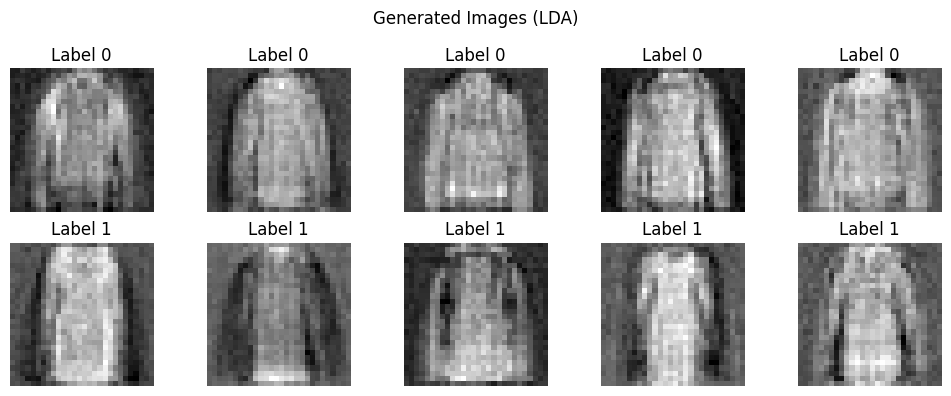

In [37]:
clflda = LinearDiscriminantAnalysis(**best_params_clflda)
clflda.fit(Xtrain_minmax, ytrain)
lda_means = clflda.means_
lda_cov = clflda.covariance_
samples_lda = [multivariate_normal(lda_means[i], lda_cov, size=5) for i in range(2)]


def plot_generated_images(samples, title):
    fig, axs = plt.subplots(2, 5, figsize=(10, 4))
    fig.suptitle(title)
    for i in range(2):
        for j in range(5):
            axs[i, j].imshow(samples[i][j].reshape(28, 28), cmap='gray')
            axs[i, j].axis('off')
            axs[i, j].set_title(f"Label {i}")
    plt.tight_layout()
    plt.show()

plot_generated_images(samples_lda, "Generated Images (LDA)")

## 3. Dimensionality reduction

### 1. PCA

#### 1. SVM

In [21]:
param_grid = {
    'n_components': range(10, 15),
    'C': range(1, 40),
    'gamma': ['scale', 'auto'],
    'kernel': ['rbf', 'linear', 'poly', 'sigmoid']
}

param_comb = ParameterGrid(param_grid)
val_metric = []

for params in param_comb:
    pca = PCA(n_components=params['n_components'], random_state=42).fit(Xtrain_minmax)
    Xtrain_pca = pca.transform(Xtrain_minmax)
    Xval_pca = pca.transform(Xval_minmax)

    clf = SVC(C=params['C'], gamma=params['gamma'], kernel=params['kernel'], random_state=42)
    clf.fit(Xtrain_pca, ytrain)

    val_metric.append(metrics.accuracy_score(yval, clf.predict(Xval_pca)))

best_params = param_comb[np.argmax(val_metric)]
best_accuracy = max(val_metric)
print(f"Best accuracy: {best_accuracy:.4f} with params: {best_params}")

Best accuracy: 0.9367 with params: {'n_components': 13, 'kernel': 'poly', 'gamma': 'auto', 'C': 2}


We can observe that applying PCA slightly decreased the validation accuracy compared to the model without dimensionality reduction. This suggests that important information might have been lost during the projection, and PCA did not provide a benefit in this case.


#### 2. Naive Bayes 

In [22]:
from sklearn.preprocessing import Binarizer

param_grid = {
    'n_components': range(1, 20),
    'var_smoothing': np.arange(1e-9, 1e-7, 1e-8),
    'normalization': [Binarizer()]
}

param_comb = ParameterGrid(param_grid)

val_metric = []
for params in param_comb:
    scaler = params['normalization'].fit(Xtrain)
    Xtrain_ = scaler.transform(Xtrain)
    Xval_ = scaler.transform(Xval)
    Xtest_ = scaler.transform(Xtest)

    pca = PCA(n_components=params['n_components'], random_state=42).fit(Xtrain_)
    Xtrain_pca = pca.transform(Xtrain_)
    Xval_pca = pca.transform(Xval_)
    Xtest_pca = pca.transform(Xtest_)

    clfGaus = GaussianNB(var_smoothing=params['var_smoothing'])
    clfGaus.fit(Xtrain_pca, ytrain)
    val_metric.append(metrics.accuracy_score(yval, clfGaus.predict(Xval_pca)))

best_params_clfGaus_pca = param_comb[np.argmax(val_metric)]
best_accuracy_clfGaus_pca = max(val_metric)

print(f"Best hyperparameters: {best_params_clfGaus_pca}")
print(f"Best validation accuracy: {best_accuracy_clfGaus_pca:.4f}")



Best hyperparameters: {'var_smoothing': np.float64(1e-09), 'normalization': Binarizer(), 'n_components': 7}
Best validation accuracy: 0.8767


Applying PCA improved the performance of Gaussian Naive Bayes. The validation accuracy increased compared to using the original features, indicating that dimensionality reduction helped the model focus on the most informative components.


#### 3. LDA

In [23]:
param_grid = {
    'n_components': range(10, 15),
    'solver': ['lsqr', 'eigen'],
    'shrinkage': np.arange(0.01, 1, 0.01),
    'n_components_lda': range(1, min(len(np.unique(ytrain)), Xtrain.shape[1])),
    'normalization': [MinMaxScaler()]
}

param_comb = ParameterGrid(param_grid)

val_metric = []
for params in param_comb:
    scaler = params['normalization'].fit(Xtrain)
    Xtrain_ = scaler.transform(Xtrain)
    Xval_ = scaler.transform(Xval)
    Xtest_ = scaler.transform(Xtest)

    pca = PCA(n_components=params['n_components'], random_state=42).fit(Xtrain_)
    Xtrain_pca = pca.transform(Xtrain_)
    Xval_pca = pca.transform(Xval_)
    Xtest_pca = pca.transform(Xtest_)

    clf_lda = LinearDiscriminantAnalysis(
        solver=params['solver'],
        shrinkage=params['shrinkage'],
        n_components=params['n_components_lda']
    )
    clf_lda.fit(Xtrain_pca, ytrain)
    val_metric.append(metrics.accuracy_score(yval, clf_lda.predict(Xval_pca)))

best_params_lda_pca = param_comb[np.argmax(val_metric)]
best_accuracy_lda_pca = max(val_metric)
print(f"Best hyperparameters: {best_params_lda_pca}")
print(f"Best validation accuracy: {best_accuracy_lda_pca:.4f}")

Best hyperparameters: {'solver': 'lsqr', 'shrinkage': np.float64(0.1), 'normalization': MinMaxScaler(), 'n_components_lda': 1, 'n_components': 13}
Best validation accuracy: 0.9267


Applying PCA slightly improved the performance of the LDA classifier, leading to higher validation accuracy.









### 2. LLE

### 1. SVM

In [24]:
param_grid = {
    'n_components': range(10, 15),
    'n_neighbors': range(10, 12),
    'C': range(1, 40),
    'gamma': ['scale', 'auto'],
    'kernel': ['rbf', 'linear', 'poly', 'sigmoid']
}

param_comb = ParameterGrid(param_grid)

val_metric = []
for params in param_comb:
    lle = LocallyLinearEmbedding(
        n_components=params['n_components'],
        n_neighbors=params['n_neighbors'],
        random_state=42
    ).fit(Xtrain_minmax)

    Xtrain_lle = lle.transform(Xtrain_minmax)
    Xval_lle = lle.transform(Xval_minmax)
    Xtest_lle = lle.transform(Xtest_minmax)

    clfSVM = SVC(
        C=params['C'],
        gamma=params['gamma'],
        kernel=params['kernel'],
        random_state=42
    )
    clfSVM.fit(Xtrain_lle, ytrain)
    val_metric.append(metrics.accuracy_score(yval, clfSVM.predict(Xval_lle)))

best_params_clfSVM_lle = param_comb[np.argmax(val_metric)]
best_accuracy_clfSVM_lle = max(val_metric)

print(f"Best hyperparameters: {best_params_clfSVM_lle}")
print(f"Best validation accuracy: {best_accuracy_clfSVM_lle:.4f}")


Best hyperparameters: {'n_neighbors': 10, 'n_components': 11, 'kernel': 'poly', 'gamma': 'scale', 'C': 1}
Best validation accuracy: 0.9300


We can observe that applying LLE slightly decreased the validation accuracy compared to the model without dimensionality reduction. This suggests that important information might have been lost during the projection, and LLE did not provide a benefit in this case. In comparing with PCA it is also worse result.


### 2. Naive Bayes

In [25]:
param_grid = {
    'n_components': range(10, 15),
    'n_neighbors': range(10, 12),
    'var_smoothing': np.arange(1e-9, 1e-7, 1e-8)
}

param_comb = ParameterGrid(param_grid)

val_metric = []
for params in param_comb:
    lle = LocallyLinearEmbedding(
        n_components=params['n_components'],
        n_neighbors=params['n_neighbors'],
        random_state=42
    ).fit(Xtrain_minmax)

    Xtrain_lle = lle.transform(Xtrain_minmax)
    Xval_lle = lle.transform(Xval_minmax)
    Xtest_lle = lle.transform(Xtest_minmax)

    clfGaus = GaussianNB(var_smoothing=params['var_smoothing'])
    clfGaus.fit(Xtrain_lle, ytrain)
    val_metric.append(metrics.accuracy_score(yval, clfGaus.predict(Xval_lle)))

best_params_clfGaus_lle = param_comb[np.argmax(val_metric)]
best_accuracy_clfGaus_lle = max(val_metric)

print(f"Best hyperparameters: {best_params_clfGaus_lle}")
print(f"Best validation accuracy: {best_accuracy_clfGaus_lle:.4f}")


Best hyperparameters: {'var_smoothing': np.float64(1e-09), 'n_neighbors': 10, 'n_components': 12}
Best validation accuracy: 0.8767


Applying LLE improved the performance of Gaussian Naive Bayes. The validation accuracy increased compared to using the original features, indicating that dimensionality reduction helped the model focus on the most informative components. Comparing with PCA it left same. 


### 3. LDA

In [26]:
param_grid = {
    'n_components': range(10, 15),
    'n_neighbors': range(10, 12),
    'solver': ['lsqr', 'eigen'],
    'shrinkage': np.arange(0.01, 1, 0.01),
    'n_components_lda': range(1, min(len(np.unique(ytrain)), Xtrain.shape[1]))
}

param_comb = ParameterGrid(param_grid)

val_metric = []
for params in param_comb:
    lle = LocallyLinearEmbedding(
        n_components=params['n_components'],
        n_neighbors=params['n_neighbors'],
        random_state=42
    ).fit(Xtrain_minmax)

    Xtrain_lle = lle.transform(Xtrain_minmax)
    Xval_lle = lle.transform(Xval_minmax)
    Xtest_lle = lle.transform(Xtest_minmax)

    clflda = LinearDiscriminantAnalysis(
        solver=params['solver'],
        shrinkage=params['shrinkage'],
        n_components=params['n_components_lda']
    )
    clflda.fit(Xtrain_lle, ytrain)
    val_metric.append(metrics.accuracy_score(yval, clflda.predict(Xval_lle)))

best_params_clflda_lle = param_comb[np.argmax(val_metric)]
best_accuracy_clflda_lle = max(val_metric)


print(f"Best hyperparameters: {best_params_clflda_lle}")
print(f"Best validation accuracy: {best_accuracy_clflda_lle:.4f}")


Best hyperparameters: {'solver': 'lsqr', 'shrinkage': np.float64(0.38), 'n_neighbors': 10, 'n_components_lda': 1, 'n_components': 12}
Best validation accuracy: 0.9067


After applying LLE before LDA, the validation accuracy decreased compared to using LDA with PCA or even LDA without dimensionality reduction. This suggests that LLE may distort the data structure in a way that is less compatible with LDA's linear assumptions.

## 4. Final model evaluation

As the final model, I selected the SVM classifier **without dimensionality reduction**, as it achieved the highest validation accuracy of **0.9467** using Min-Max scaling and the following hyperparameters: `kernel='rbf'`, `gamma='auto'`, and `C=13`.


In [27]:
clfSVMb = SVC(C=13, gamma='auto', kernel='rbf', random_state=42)
clfSVMb.fit(Xtrain_minmax, ytrain)

SVC(C=13, gamma='auto', random_state=42)

In [28]:
eval_df = pd.read_csv("evaluate.csv")
eval_df.head()
ids = eval_df['ID']
eval_df = eval_df.drop(columns=['ID'])

In [29]:
eval_df.head()

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,1,0,0,...,87,5,0,0,1,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,2,0,15,144,139,0,0,0,0,0
4,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


Normalize and predict.

In [30]:
eval_df_minmax = scaler_minmax.transform(eval_df)

In [31]:
eval_pred = clfSVMb.predict(eval_df_minmax)

Saving results.

In [32]:
result = pd.DataFrame({
    'ID': ids,
    'label': eval_pred
})

In [33]:
result.to_csv('result.csv', index=False)

## The end.